<center><h1>Xie_Chong_HW8</h1></center>

Name: Chong Xie
<br>
Github Username: cxieusc
<br>
USC ID: 6800668300

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.utils.extmath import softmax

import warnings
warnings.filterwarnings("ignore")

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
features = [
    'radius', 'texture', 'perimeter', 'area', 'smoothness',
    'compactness', 'concavity', 'concave_points',
    'symmetry', 'fractal_dimension'
]
columns = ['id', 'diagnosis'] + [
    f'{feature}_{stat}'
    for stat in ['mean', 'se', 'worst']
    for feature in features
]
df = pd.read_csv('../data/wdbc.data', header=None, names=columns)
df.head(3)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

In [3]:
X = df.drop(['id', 'diagnosis'], axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [4]:
pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('svm', LinearSVC(
        penalty='l1',
        dual=False,
        max_iter=100000,
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    pipeline,
    param_grid={'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

print('Best C:', search.best_params_['svm__C'])
print('Best CV accuracy:', search.best_score_)

Best C: 10
Best CV accuracy: 0.9692307692307691


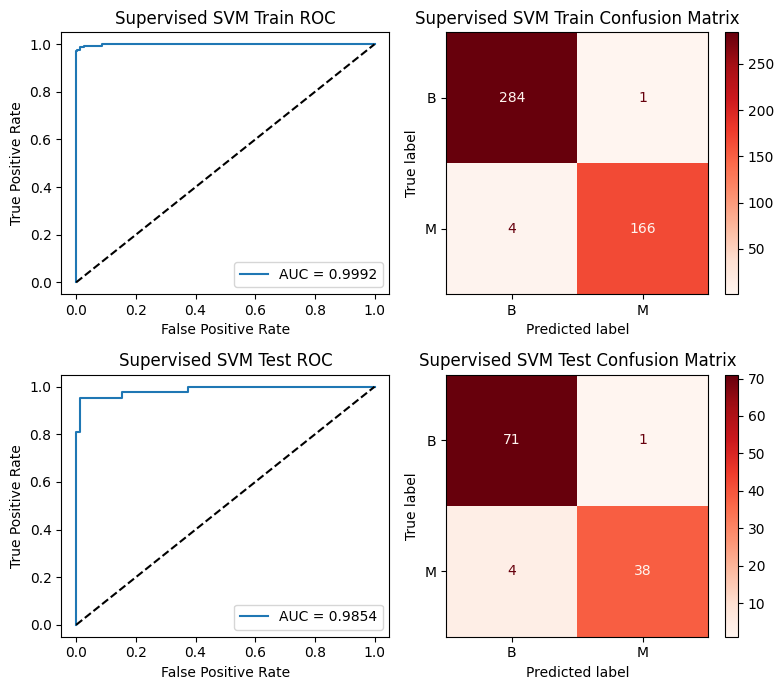

In [21]:
def plot_svm_results(model, method_name):
    fig, axes = plt.subplots(2, 2, figsize=(8, 7))

    for row, split, X_part, y_part in [
        (0, 'Train', X_train, y_train),
        (1, 'Test', X_test, y_test)
    ]:
        predictions = model.predict(X_part)
        scores = model.decision_function(X_part)

        fpr, tpr, _ = roc_curve(
            y_part, scores, pos_label='M'
        )
        auc_value = roc_auc_score(y_part, scores)

        axes[row, 0].plot(
            fpr, tpr,
            label=f'AUC = {auc_value:.4f}'
        )
        axes[row, 0].plot([0, 1], [0, 1], 'k--')
        axes[row, 0].set(
            xlabel='False Positive Rate',
            ylabel='True Positive Rate',
            title=f'{method_name} {split} ROC'
        )
        axes[row, 0].legend()

        ConfusionMatrixDisplay.from_predictions(
            y_part,
            predictions,
            labels=['B', 'M'],
            cmap='Reds',
            ax=axes[row, 1]
        )
        axes[row, 1].set_title(
            f'{method_name} {split} Confusion Matrix'
        )

    plt.tight_layout()
    plt.show()


plot_svm_results(search.best_estimator_, 'Supervised SVM')

##### Run 30 times

In [5]:
def fit_svm(X_fit, y_fit, seed):
    estimator = Pipeline([
        ('scaler', MinMaxScaler()),
        ('svm', LinearSVC(
            penalty='l1',
            dual=False,
            max_iter=100000,
            random_state=seed
        ))
    ])

    search_cv = GridSearchCV(
        estimator,
        param_grid={'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]},
        scoring='accuracy',
        cv=StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        ),
        n_jobs=-1
    )

    search_cv.fit(X_fit, y_fit)
    return search_cv.best_estimator_


def evaluate_svm(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    scores = model.decision_function(X_eval)

    return {
        'Accuracy': accuracy_score(y_eval, predictions),
        'Precision': precision_score(
            y_eval, predictions, pos_label='M', zero_division=0
        ),
        'Recall': recall_score(
            y_eval, predictions, pos_label='M', zero_division=0
        ),
        'F1': f1_score(
            y_eval, predictions, pos_label='M', zero_division=0
        ),
        'AUC': roc_auc_score(y_eval, scores)
    }

In [6]:
supervised_results = []

for run in range(30):
    seed = 42 + run

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=seed
    )

    supervised_model = fit_svm(X_tr, y_tr, seed)

    for split, X_part, y_part in [
        ('Train', X_tr, y_tr),
        ('Test', X_te, y_te)
    ]:
        supervised_results.append({
            'Run': run + 1,
            'Dataset': split,
            **evaluate_svm(supervised_model, X_part, y_part)
        })

    if (run + 1) % 10 == 0:
        print(f'Finished run {run + 1}/30')

supervised_results_df = pd.DataFrame(supervised_results)

metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

supervised_summary = (
    supervised_results_df
    .groupby('Dataset')[metric_columns]
    .mean()
    .reindex(['Train', 'Test'])
)

display(supervised_summary)

Finished run 10/30
Finished run 20/30
Finished run 30/30


,Accuracy,Precision,Recall,F1,AUC
Dataset,,,,,
Train,0.985055,0.991006,0.968824,0.979764,0.997459
Test,0.972222,0.974168,0.950794,0.961908,0.993419


#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [7]:
X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.5,
    stratify=y_train,
    random_state=42
)

In [8]:
semi_search = GridSearchCV(
    pipeline,
    param_grid={'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

semi_search.fit(X_labeled, y_labeled)

print('Best C:', semi_search.best_params_['svm__C'])
print('Best CV accuracy:', semi_search.best_score_)

semi_model = semi_search.best_estimator_

Best C: 1
Best CV accuracy: 0.9647342995169084


##### (B)

In [9]:
while len(X_unlabeled) > 0:
    scores = semi_model.decision_function(X_unlabeled)
    position = abs(scores).argmax()
    selected_X = X_unlabeled.iloc[[position]]

    pseudo_y = pd.Series(
        semi_model.predict(selected_X),
        index=selected_X.index,
        name=y_labeled.name
    )

    X_labeled = pd.concat([X_labeled, selected_X])
    y_labeled = pd.concat([y_labeled, pseudo_y])
    X_unlabeled = X_unlabeled.drop(index=selected_X.index)

    semi_model.fit(X_labeled, y_labeled)

print('Final training size:', len(X_labeled))
print('Remaining unlabeled samples:', len(X_unlabeled))

Final training size: 455
Remaining unlabeled samples: 0


In [10]:
results = []

for split, X_part, y_part in [
    ('Train', X_train, y_train),
    ('Test', X_test, y_test)
]:
    predictions = semi_model.predict(X_part)
    scores = semi_model.decision_function(X_part)

    results.append({
        'Dataset': split,
        'Accuracy': accuracy_score(y_part, predictions),
        'Precision': precision_score(
            y_part, predictions, pos_label='M', zero_division=0
        ),
        'Recall': recall_score(
            y_part, predictions, pos_label='M', zero_division=0
        ),
        'F1': f1_score(
            y_part, predictions, pos_label='M', zero_division=0
        ),
        'AUC': roc_auc_score(y_part, scores)
    })

display(pd.DataFrame(results).set_index('Dataset'))

,Accuracy,Precision,Recall,F1,AUC
Dataset,,,,,
Train,0.971429,0.975758,0.947059,0.961194,0.994180
Test,0.973684,0.975610,0.952381,0.963855,0.997024


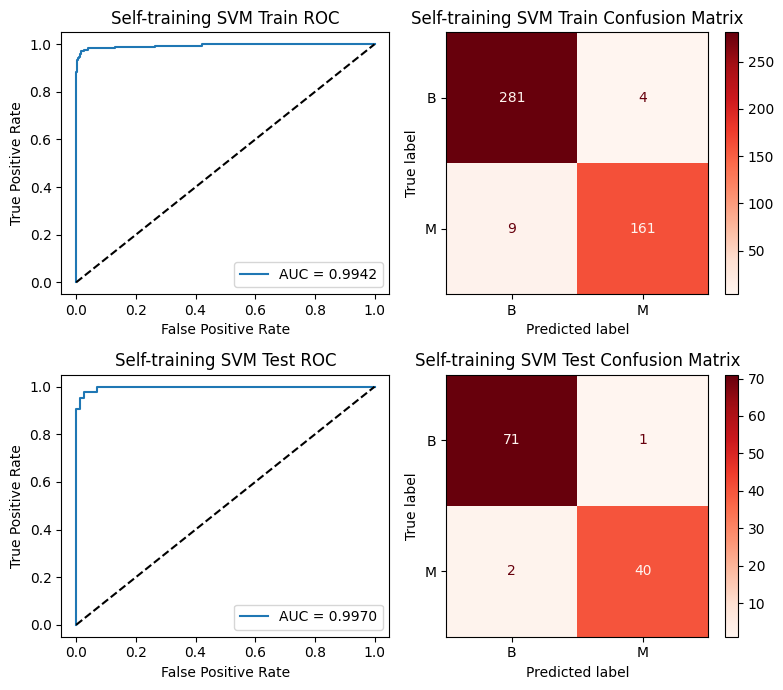

In [22]:
plot_svm_results(semi_model, 'Self-training SVM')

##### Run 30 times

In [11]:
self_training_results = []

for run in range(30):
    seed = 42 + run

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=seed
    )

    X_lab, X_pool, y_lab, _ = train_test_split(
        X_tr, y_tr,
        train_size=0.5,
        stratify=y_tr,
        random_state=seed
    )

    self_training_model = fit_svm(X_lab, y_lab, seed)

    while len(X_pool) > 0:
        scores = self_training_model.decision_function(X_pool)
        position = abs(scores).argmax()
        selected_X = X_pool.iloc[[position]]

        pseudo_y = pd.Series(
            self_training_model.predict(selected_X),
            index=selected_X.index,
            name=y_lab.name
        )

        X_lab = pd.concat([X_lab, selected_X])
        y_lab = pd.concat([y_lab, pseudo_y])
        X_pool = X_pool.drop(index=selected_X.index)

        self_training_model.fit(X_lab, y_lab)

    for split, X_part, y_part in [
        ('Train', X_tr, y_tr),
        ('Test', X_te, y_te)
    ]:
        self_training_results.append({
            'Run': run + 1,
            'Dataset': split,
            **evaluate_svm(self_training_model, X_part, y_part)
        })
    
    if (run + 1) % 10 == 0:
        print(f'Finished run {run + 1}/30')

self_training_results_df = pd.DataFrame(self_training_results)

metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

self_training_summary = (
    self_training_results_df
    .groupby('Dataset')[metric_columns]
    .mean()
    .reindex(['Train', 'Test'])
)

display(self_training_summary)

Finished run 10/30
Finished run 20/30
Finished run 30/30


,Accuracy,Precision,Recall,F1,AUC
Dataset,,,,,
Train,0.973773,0.982920,0.946471,0.964098,0.993607
Test,0.963158,0.964749,0.935714,0.949082,0.990112


#### (iii) Unsupervised Learning

##### (A)

In [12]:
kmeans_scaler = MinMaxScaler()
X_train_scaled = kmeans_scaler.fit_transform(X_train)

kmeans = KMeans(
    n_clusters=2,
    n_init=30,
    random_state=42
)

train_clusters = kmeans.fit_predict(X_train_scaled)

print('Inertia:', kmeans.inertia_)
print('Cluster sizes:', np.bincount(train_clusters))

Inertia: 181.37013312430904
Cluster sizes: [298 157]


K-means is run with 30 randomized initializations, and the solution with the smallest inertia is retained. Multiple initializations reduce the risk of a poor local optimum, but do not guarantee the global optimum.

##### (B)

In [13]:
train_distances = kmeans.transform(X_train_scaled)

cluster_labels = []

for cluster_id in range(2):
    nearest_positions = np.argsort(
        train_distances[:, cluster_id]
    )[:30]

    nearest_labels = y_train.iloc[nearest_positions]
    counts = nearest_labels.value_counts()

    label = 'M' if counts.get('M', 0) > counts.get('B', 0) else 'B'
    cluster_labels.append(label)

    print(
        f'Cluster {cluster_id}: '
        f'{counts.to_dict()} -> {label}'
    )

cluster_labels = np.array(cluster_labels)
train_predictions = cluster_labels[train_clusters]

cluster_weights = softmax(-train_distances)
train_scores = cluster_weights[:, cluster_labels == 'M'].sum(axis=1)
kmeans_train_results = {
    'Accuracy': accuracy_score(y_train, train_predictions),
    'Precision': precision_score(
        y_train, train_predictions, pos_label='M', zero_division=0
    ),
    'Recall': recall_score(
        y_train, train_predictions, pos_label='M', zero_division=0
    ),
    'F1': f1_score(
        y_train, train_predictions, pos_label='M', zero_division=0
    ),
    'AUC': roc_auc_score(y_train, train_scores)
}

display(pd.DataFrame(kmeans_train_results, index=['Train']))

Cluster 0: {'B': 30} -> B
Cluster 1: {'M': 30} -> M


,Accuracy,Precision,Recall,F1,AUC
Train,0.923077,0.929936,0.858824,0.892966,0.977049


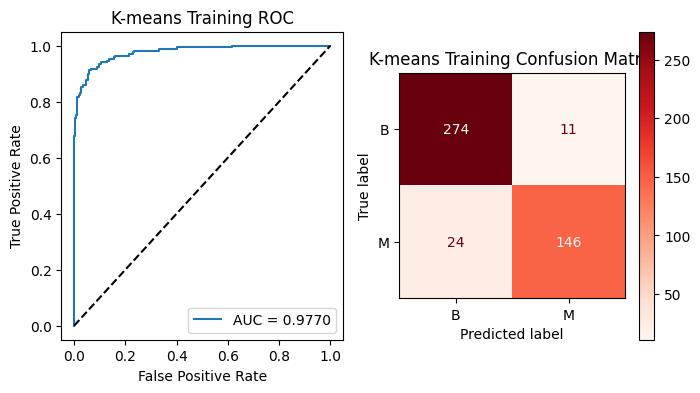

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

fpr, tpr, _ = roc_curve(
    y_train, train_scores, pos_label='M'
)

axes[0].plot(
    fpr, tpr,
    label=f"AUC = {kmeans_train_results['AUC']:.4f}"
)
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set(
    xlabel='False Positive Rate',
    ylabel='True Positive Rate',
    title='K-means Training ROC'
)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_train,
    train_predictions,
    labels=['B', 'M'],
    cmap='Reds',
    ax=axes[1]
)
axes[1].set_title('K-means Training Confusion Matrix')

plt.show()

##### (C)

In [15]:
def kmeans_metrics(y_true, predictions, scores):
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(
            y_true, predictions, pos_label='M', zero_division=0
        ),
        'Recall': recall_score(
            y_true, predictions, pos_label='M', zero_division=0
        ),
        'F1': f1_score(
            y_true, predictions, pos_label='M', zero_division=0
        ),
        'AUC': roc_auc_score(y_true, scores)
    }

In [16]:
X_test_scaled = kmeans_scaler.transform(X_test)

test_clusters = kmeans.predict(X_test_scaled)
test_predictions = cluster_labels[test_clusters]

test_distances = kmeans.transform(X_test_scaled)
test_weights = softmax(-test_distances)
test_scores = test_weights[:, cluster_labels == 'M'].sum(axis=1)

kmeans_test_results = kmeans_metrics(
    y_test, test_predictions, test_scores
)

display(pd.DataFrame(
    [kmeans_train_results, kmeans_test_results],
    index=['Train', 'Test']
))

,Accuracy,Precision,Recall,F1,AUC
Train,0.923077,0.929936,0.858824,0.892966,0.977049
Test,0.921053,0.971429,0.809524,0.883117,0.986111


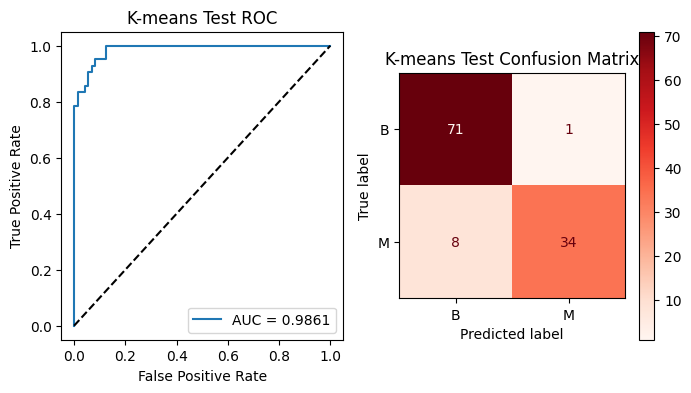

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

fpr, tpr, _ = roc_curve(
    y_test, test_scores, pos_label='M'
)

axes[0].plot(
    fpr, tpr,
    label=f"AUC = {kmeans_test_results['AUC']:.4f}"
)
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set(
    xlabel='False Positive Rate',
    ylabel='True Positive Rate',
    title='K-means Test ROC'
)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=['B', 'M'],
    cmap='Reds',
    ax=axes[1]
)
axes[1].set_title('K-means Test Confusion Matrix')

plt.show()

##### Run 30 times

In [18]:
kmeans_results = []

# Run 30 times of K-means
for run in range(30):
    seed = 42 + run

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=seed
    )

    scaler = MinMaxScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_te_scaled = scaler.transform(X_te)

    model = KMeans(
        n_clusters=2,
        n_init=30,
        random_state=seed
    )
    model.fit(X_tr_scaled)

    distances = model.transform(X_tr_scaled)
    labels = []

    for cluster_id in range(2):
        positions = np.argsort(distances[:, cluster_id])[:30]
        counts = y_tr.iloc[positions].value_counts()

        label = (
            'M' if counts.get('M', 0) > counts.get('B', 0)
            else 'B'
        )
        labels.append(label)

    labels = np.array(labels)

    for split, X_part, y_part in [
        ('Train', X_tr_scaled, y_tr),
        ('Test', X_te_scaled, y_te)
    ]:
        predictions = labels[model.predict(X_part)]

        weights = softmax(-model.transform(X_part))
        scores = weights[:, labels == 'M'].sum(axis=1)

        kmeans_results.append({
            'Run': run + 1,
            'Dataset': split,
            **kmeans_metrics(y_part, predictions, scores)
        })

kmeans_results_df = pd.DataFrame(kmeans_results)

metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

kmeans_summary = (
    kmeans_results_df
    .groupby('Dataset')[metric_columns]
    .mean()
    .reindex(['Train', 'Test'])
)

display(kmeans_summary)

,Accuracy,Precision,Recall,F1,AUC
Dataset,,,,,
Train,0.924835,0.948756,0.844902,0.893569,0.980159
Test,0.929532,0.950140,0.854762,0.898913,0.980930


#### (iv) Spectral Clustering

#### (v) Compare

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

#### (ii) Active

### (c) Average the 50 test errors